# 1. Problem: diffuse fluorescence localization


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`fluorescence`，shape `(1, 56)`，dtype `<f8`：Observed processed probe fluorescence, instrument-relative intensity units.；`excitation`，shape `(1, 56)`，dtype `<f8`：Observed excitation for the same channels, instrument-relative intensity units.；`links`，shape `(1, 56, 2)`，dtype `<i8`：Source and detector indices per channel, dimensionless.；`nodes`，shape `(1, 5707, 3)`，dtype `<f8`：Tissue FEM coordinates, XYZ in mm.；`tetrahedra`，shape `(1, 29448, 4)`，dtype `<i8`：Tissue-node indices per tetrahedron, dimensionless.；`boundary_vertices`，shape `(1, 5707)`，dtype `|b1`：Known boundary-vertex indicator, dimensionless; exterior faces follow from connectivity.；`source_positions`，shape `(1, 8, 3)`，dtype `<f8`：Model point sources displaced inward by the author's optical-transport convention, XYZ in mm.；`detector_positions`，shape `(1, 8, 3)`，dtype `<f8`：Surface detector coordinates, XYZ in mm.；`coarse_nodes`，shape `(1, 3323, 3)`，dtype `<f8`：Fixed geometry-only reconstruction-basis coordinates, XYZ in mm.；`coarse_tetrahedra`，shape `(1, 17350, 4)`，dtype `<i8`：Reconstruction-basis connectivity, dimensionless indices.。未知量为5707节点鼠头荧光yield，mm^-1。

获取模型：耦合激发/发射扩散PDE及Robin边界，发射源为q乘激发fluence；实际光通道取样。

如何恢复：src.solvers.reconstruct/initialize_uniform：FEM与粗细网格unguided正则化迭代。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell3光通道与MRI网格；6主动yield；8–11切面/参考、56通道残差、正则化及边界敏感性。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留6个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。仅方法参考，没有独立荧光yield解剖真值；上游Robin限定/纠正需保持注明。

<!-- inverse-evidence-audit:20261026:end -->


Reconstruct the complete spatial fluorescence-yield field from eight illuminations and seven other detectors per illumination. These are **real author-supplied measurements** of an EGFR-targeted probe in a mouse head. The independent MRI supplies geometry, not molecular truth. All 56 optical channels and all 5,707 fine nodes remain in the benchmark.

The selected baseline is the author's full three-dimensional unguided tutorial pipeline. The 2010 paper also compares anatomical-prior methods and animal populations; those are not reproduced here because only this tutorial acquisition and its unguided binding are supplied. A homogeneous field is an active physically matched comparator. No diagnostic classification or independent localization accuracy is claimed.

## Current benchmark contract v2

The task now asks for a nonnegative measurement-consistent conditional field, with no unique spatial truth certification. The independent P1 FEM evaluates all 56 calibrated observations; mean squared log-residual excess <=1e-6 and the original relative L2 <=0.191 remain. GN damping 10 is a numerical update setting, not a static Tikhonov prior. An independent complete 56x5707 adjoint sensitivity matrix and NNLS-derived improved feasible field pass; zero/scaled/spatially permuted fields fail. The source reconstruction is unchanged. Earlier displayed agreement metrics are historical v1, not current acceptance boundaries.


In [1]:
from pathlib import Path
import os,sys,time,json,hashlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
if not (ROOT/'src').exists():ROOT=ROOT.parent
assert (ROOT/'src').exists(),ROOT
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_raw,geometry_operators
from src.physics_model import assemble_fem,forward_fluorescence,MUAM,KAPPAM
from src.solvers import reconstruct
from src.visualization import metrics,slice_field,export_figure
from scipy.sparse.linalg import splu
plt.rcParams.update({'font.size':10,'figure.dpi':110,'axes.grid':False})
raw=load_raw(ROOT/'data/raw_data.npz');nodes=raw['nodes'];elements=raw['tetrahedra']
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as f:qualified_upstream=f['reconstruction'][0]
with np.load(ROOT/'notebooks/reference_outputs/original_incomplete_robin.npz',allow_pickle=False) as f:original_upstream=f['reconstruction'][0];original_objective=f['projection_error'][0]
with np.load(ROOT/'notebooks/reference_outputs/qualified_upstream_measurements.npz',allow_pickle=False) as f:upstream_objective=f['objective_history'][0];upstream_prediction=f['prediction'][0]
def show(fig,label,**numeric):
 export_figure(fig,label,numeric);plt.show();plt.close(fig)
print('Raw SHA256',hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())
print('NumPy',np.__version__,'all nodes',len(nodes),'all pairs',len(raw['links']))

Raw SHA256 c0ad7de1ab6a7d24d4e33b1bfcb8c451976bfbd1e884bb23da23e648426c06c9
NumPy 2.4.6 all nodes 5707 all pairs 56


# 2. Data: geometry and every optical channel

Coordinates below are the native author mesh coordinates in millimetres. The coarse mesh is a geometry-only numerical basis with 3,323 retained nodes. It contains no reconstructed field or anatomical labels. Measured intensities are already spectrally processed; this task starts at the diffusion-tomography stage rather than reproducing unavailable spectrometer unmixing. A separate data redistribution license was not supplied in the sample collection; the code BSD license does not imply a data license.

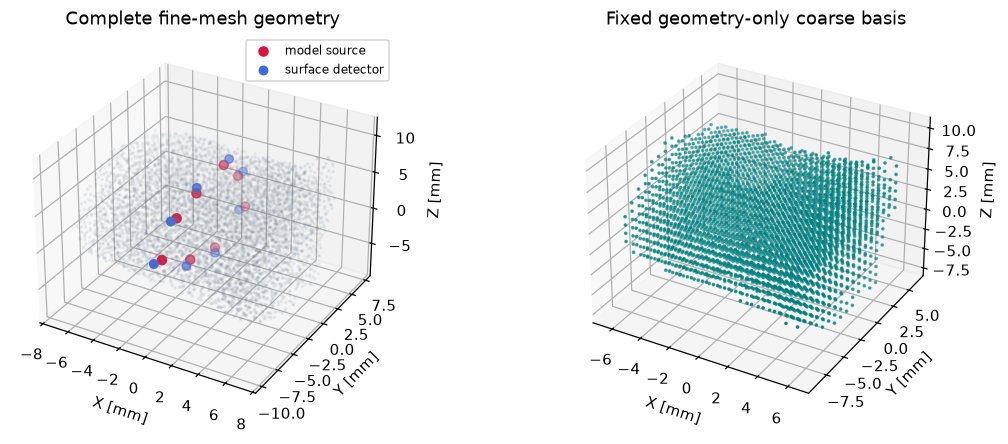

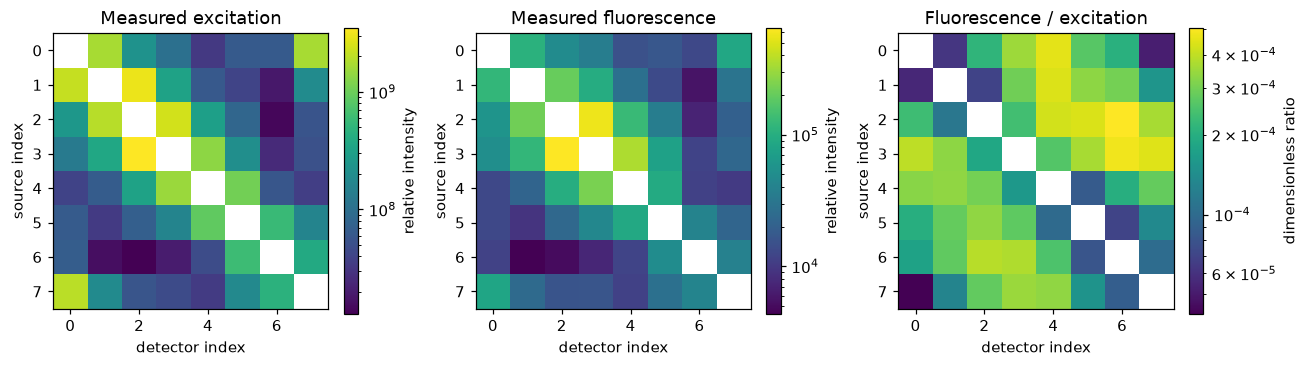

In [2]:
fig=plt.figure(figsize=(11,4));ax=fig.add_subplot(121,projection='3d');ax.scatter(*nodes.T,s=2,alpha=.35,c='slategray');ax.scatter(*raw['source_positions'].T,c='crimson',s=35,label='model source');ax.scatter(*raw['detector_positions'].T,c='royalblue',s=30,label='surface detector');ax.set(xlabel='X [mm]',ylabel='Y [mm]',zlabel='Z [mm]',title='Complete fine-mesh geometry');ax.legend(fontsize=8)
ax=fig.add_subplot(122,projection='3d');ax.scatter(*raw['coarse_nodes'].T,s=2,c='teal');ax.set(xlabel='X [mm]',ylabel='Y [mm]',zlabel='Z [mm]',title='Fixed geometry-only coarse basis');fig.tight_layout();show(fig,'figure01_geometry',fine_nodes=nodes,coarse_nodes=raw['coarse_nodes'],source_positions=raw['source_positions'],detector_positions=raw['detector_positions'])
fig,axes=plt.subplots(1,3,figsize=(12,3.7));source,det=raw['links'].T
for ax,values,title in zip(axes,[raw['excitation'],raw['fluorescence'],raw['fluorescence']/raw['excitation']],['Measured excitation','Measured fluorescence','Fluorescence / excitation']):
 image=np.full((8,8),np.nan);image[source,det]=values;im=ax.imshow(image,norm=LogNorm(vmin=values.min(),vmax=values.max()),cmap='viridis');ax.set(xlabel='detector index',ylabel='source index',title=title);fig.colorbar(im,ax=ax,fraction=.047,label='relative intensity' if '/' not in title else 'dimensionless ratio')
fig.tight_layout();show(fig,'figure02_all_measurements',excitation=raw['excitation'],fluorescence=raw['fluorescence'],links=raw['links'])

# 3. Physics: coupled diffusion and the boundary qualification

For excitation fluence $u$, emission fluence $v$ and yield $q$, solve

$$
A_xu=s,\qquad A_mv=M(q\odot u),\qquad
A=\kappa K+\mu M+R.
$$

The tetrahedral P1 mass is $V(1+\delta_{ij})/20$, where $V$ is tetrahedron volume and $\delta$ is the Kronecker delta. Robin face blocks are $\xi S(1+\delta_{ij})/12$, with triangle area $S$ and the README's Fresnel coefficient $\xi$. The fixed optical coefficients are assumed author-supplied model inputs; independent measurements of them are not provided.

Independent topology checks found that the original assembly selects 364 interior triangles and omits 401 true exterior triangles in this mesh. A narrowly qualified source implementation integrates all 3,624 true exterior faces. Its assembled matrix agrees with independent exact P1 integration to relative $3.84\times10^{-16}$; constant-field boundary flux agrees to $1.22\times10^{-16}$. No PDE, observations, mesh, source/detector configuration, calibration or inverse update was changed. Both the deficient original and qualified native full runs are retained separately.

The calibrated datum is $y=F X^{\mathrm{model}}/X$, using observed fluorescence $F$, observed excitation $X$ and freshly predicted excitation. All products and divisions are channelwise.

# 4. Method: active complete reconstruction

The homogeneous starting yield is recomputed from the observed log-amplitudes by source derivative bisection. The original continuum sensitivity is $J^{\mathrm{pre}}_{ri}=\int N_i u_s\overline{a_d}\,dV$, with adjoint $a_d$ retaining the original phase convention. This is an **inexact** sensitivity for the nodal-product source, not its exact discrete derivative.

Let $B$ interpolate coarse values to the fine mesh, $C$ interpolate fine values to coarse nodes, $c=Cq$, $d=\log y-\log f$, and $W=\operatorname{Re}(J^{\mathrm{pre}}/f)B\operatorname{diag}(c)$, where $f$ is the current full forward prediction. The relative-coordinate damped update is

$$
\Delta c=\operatorname{diag}(c)W^T[WW^T+rI]^{-1}d,
\qquad r=10\max_i(WW^T)_{ii}.
$$

The source stops at no more than 2% objective reduction, with a maximum of 40 evaluations. The measured evaluation count is not forced. No anatomical prior, filtered image, omitted node, output scaling or stored reconstruction is used in the fresh call below.

{
  "fresh_seconds": 3.402930300013395,
  "objective_evaluations": 13,
  "uniform_initial_muaf_mm_inverse": 4.611025315213203e-05,
  "all_node_comparison_to_qualified_upstream": {
    "ncc": 0.9999999999999996,
    "dr_nrmse": 1.334059709477387e-12,
    "max_abs_mm_inverse": 1.623406406048647e-16
  },
  "full56_forward_relative_L2": 0.18907149090792041
}


{'yield_ncc': 0.9999999999999996, 'yield_nrmse': 1.334059709477387e-12, 'yield_max_abs': 1.623406406048647e-16, 'forward_relative_L2': 0.1890714909079204}


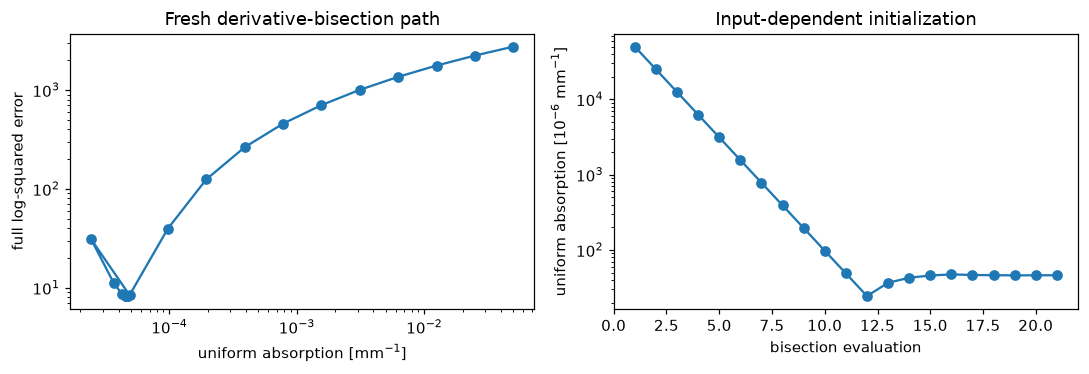

In [3]:
start=time.perf_counter();fresh=reconstruct(raw);runtime=time.perf_counter()-start;x=fresh['reconstruction'];comparison=metrics(x,qualified_upstream)
print(json.dumps({'fresh_seconds':runtime,'objective_evaluations':len(fresh['objective_history']),'uniform_initial_muaf_mm_inverse':fresh['initial_muaf'],'all_node_comparison_to_qualified_upstream':comparison,'full56_forward_relative_L2':fresh['forward_relative_L2']},indent=2))
(ROOT/'output').mkdir(exist_ok=True);np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=x[None].astype(np.float64))
import importlib.util
spec=importlib.util.spec_from_file_location('notebook_independent_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge);report=judge.evaluate(ROOT/'output/reconstruction.npz');assert report['passed'],report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8');print(report['metrics'])
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_cleaned_measurements.npz',prediction=fresh['prediction'][None],calibrated_observation=fresh['calibrated_observation'][None],objective_history=fresh['objective_history'][None],metrics=np.array([[comparison['ncc'],comparison['dr_nrmse'],comparison['max_abs_mm_inverse'],fresh['forward_relative_L2']]]))
source,D,adj,C,B=geometry_operators(raw);Am,mass,vol=assemble_fem(nodes,elements,MUAM,KAPPAM);lu=splu(Am)
uniform=np.full(len(nodes),.1*fresh['initial_muaf']);uniform_prediction,_=forward_fluorescence(uniform,fresh['phix'],mass,lu,D,raw['links'])
fig,axes=plt.subplots(1,2,figsize=(10,3.5));h=fresh['initial_history'];axes[0].semilogx(h[:,0],h[:,1],'o-');axes[0].set(xlabel='uniform absorption [mm$^{-1}$]',ylabel='full log-squared error',title='Fresh derivative-bisection path');axes[1].plot(np.arange(1,len(h)+1),h[:,0]*1e6,'o-');axes[1].set(xlabel='bisection evaluation',ylabel='uniform absorption [$10^{-6}$ mm$^{-1}$]',title='Input-dependent initialization');axes[0].set_yscale('log');axes[1].set_yscale('log');fig.tight_layout();show(fig,'figure03_initialization',initialization_history=h)


# 5. Results: actual fields, residuals and sensitivity

Upstream comparisons below refer to fresh native runs on these exact observations. The qualified source is the standard-method reference; the original incomplete-boundary output is an explicitly deficient source comparison. Neither is biological truth. Display slices use P1 interpolation only inside the known tissue geometry; all benchmark scores use the complete original node vector.

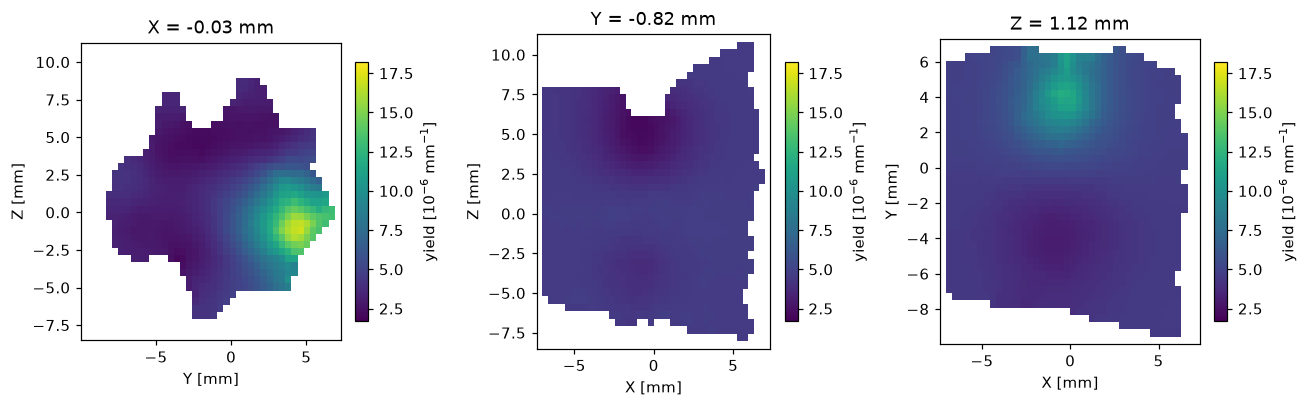

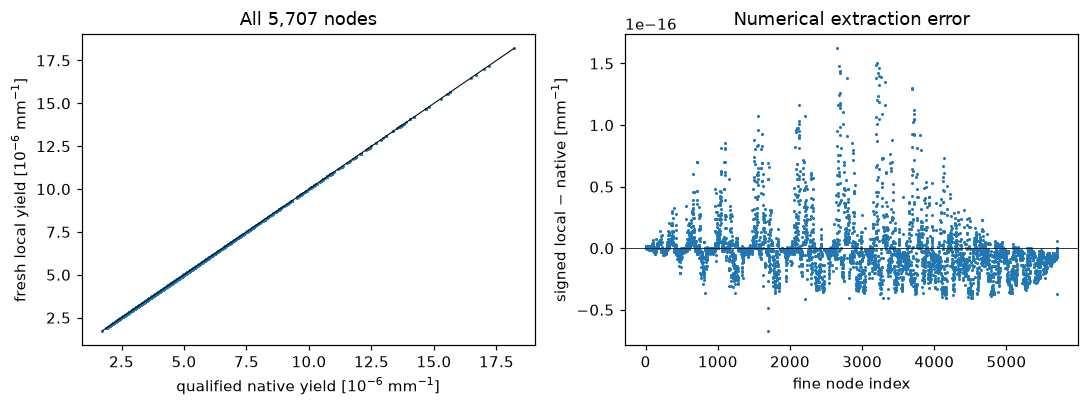

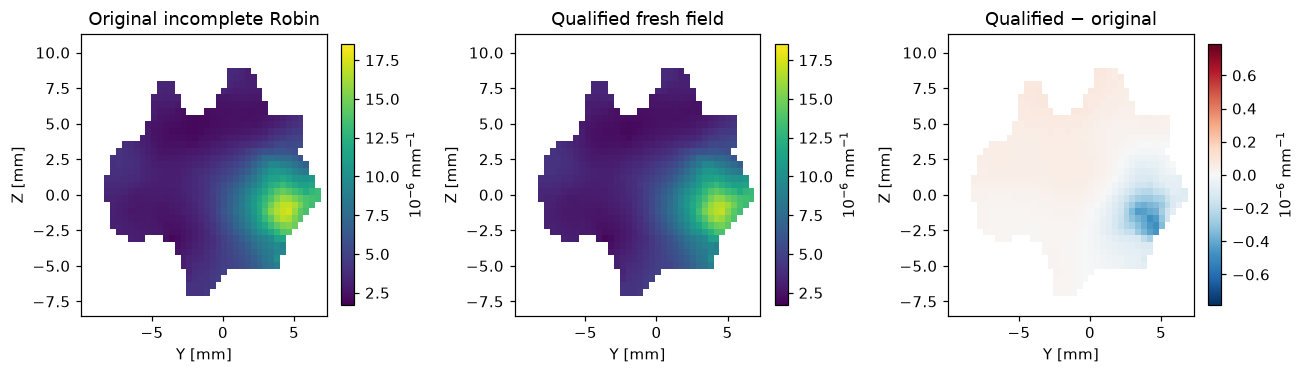

In [4]:
center=np.mean(nodes,axis=0);fig,axes=plt.subplots(1,3,figsize=(12,3.8));planes=[]
for axis,ax in enumerate(axes):
 a,b,v=slice_field(nodes,elements,x,axis,center[axis]);planes.append(v);im=ax.pcolormesh(a,b,v*1e6,shading='auto',cmap='viridis',vmin=x.min()*1e6,vmax=x.max()*1e6);other=[j for j in range(3) if j!=axis];ax.set(xlabel='XYZ'[other[0]]+' [mm]',ylabel='XYZ'[other[1]]+' [mm]',title='XYZ'[axis]+f' = {center[axis]:.2f} mm');ax.set_aspect('equal');fig.colorbar(im,ax=ax,label='yield [$10^{-6}$ mm$^{-1}$]',fraction=.045)
fig.tight_layout();show(fig,'figure04_orthogonal_yield',fine_yield=x,planes=np.asarray(planes),slice_coordinates=center)
fig,axes=plt.subplots(1,2,figsize=(10,3.8));axes[0].plot(qualified_upstream*1e6,x*1e6,'.',ms=2);axes[0].plot([qualified_upstream.min()*1e6,qualified_upstream.max()*1e6],[qualified_upstream.min()*1e6,qualified_upstream.max()*1e6],color='k',lw=.7);axes[0].set(xlabel='qualified native yield [$10^{-6}$ mm$^{-1}$]',ylabel='fresh local yield [$10^{-6}$ mm$^{-1}$]',title='All 5,707 nodes');axes[1].plot(x-qualified_upstream,'.',ms=2);axes[1].axhline(0,color='k',lw=.5);axes[1].set(xlabel='fine node index',ylabel='signed local − native [mm$^{-1}$]',title='Numerical extraction error');fig.tight_layout();show(fig,'figure05_upstream_parity',native=qualified_upstream,fresh=x,error=x-qualified_upstream)
fig,axes=plt.subplots(1,3,figsize=(12,3.5));difference=x-original_upstream;lim=np.max(abs(difference))*1e6
for ax,values,title,signed in zip(axes,[original_upstream,x,difference],['Original incomplete Robin','Qualified fresh field','Qualified − original'],[False,False,True]):
 a,b,v=slice_field(nodes,elements,values,0,center[0]);im=ax.pcolormesh(a,b,v*1e6,shading='auto',cmap='RdBu_r' if signed else 'viridis',vmin=-lim if signed else min(x.min(),original_upstream.min())*1e6,vmax=lim if signed else max(x.max(),original_upstream.max())*1e6);ax.set(xlabel='Y [mm]',ylabel='Z [mm]',title=title);ax.set_aspect('equal');fig.colorbar(im,ax=ax,fraction=.045,label='$10^{-6}$ mm$^{-1}$')
fig.tight_layout();show(fig,'figure06_boundary_qualification',original_incomplete=original_upstream,qualified_fresh=x,difference=difference)


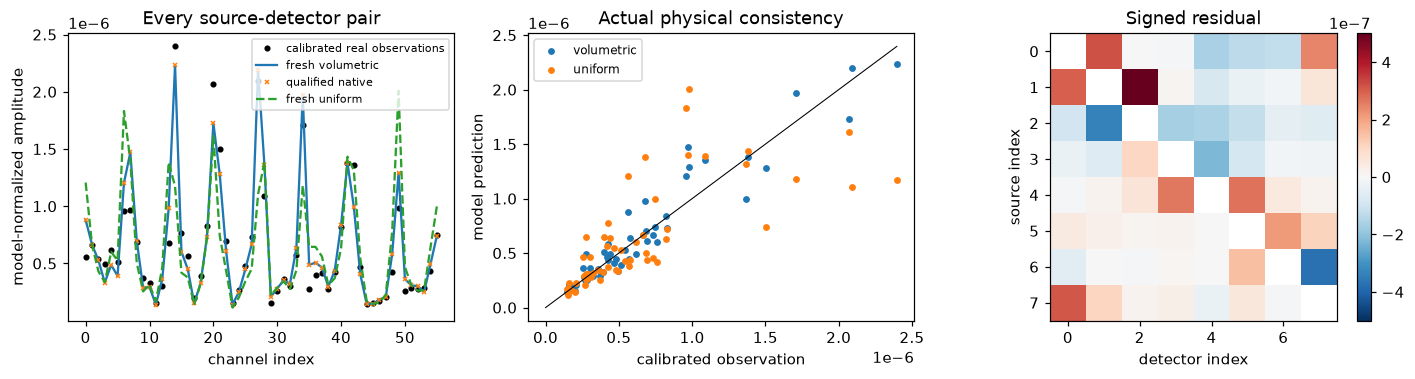

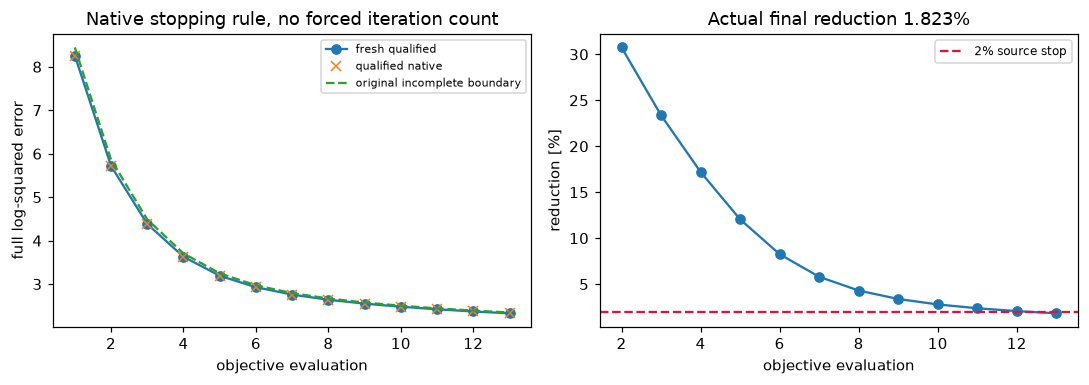

In [5]:
observed=fresh['calibrated_observation'];pred=fresh['prediction'];res=pred-observed
fig,axes=plt.subplots(1,3,figsize=(13,3.7));axes[0].plot(observed,'ko',ms=3,label='calibrated real observations');axes[0].plot(pred,'-',label='fresh volumetric');axes[0].plot(upstream_prediction,'x',ms=3,label='qualified native');axes[0].plot(uniform_prediction,'--',label='fresh uniform');axes[0].set(xlabel='channel index',ylabel='model-normalized amplitude',title='Every source-detector pair');axes[0].legend(fontsize=7)
axes[1].scatter(observed,pred,s=12,label='volumetric');axes[1].scatter(observed,uniform_prediction,s=12,label='uniform');axes[1].plot([0,observed.max()],[0,observed.max()],color='k',lw=.7);axes[1].set(xlabel='calibrated observation',ylabel='model prediction',title='Actual physical consistency');axes[1].legend(fontsize=8)
image=np.full((8,8),np.nan);image[raw['links'][:,0],raw['links'][:,1]]=res;lim=abs(res).max();im=axes[2].imshow(image,cmap='RdBu_r',vmin=-lim,vmax=lim);axes[2].set(xlabel='detector index',ylabel='source index',title='Signed residual');fig.colorbar(im,ax=axes[2],fraction=.046)
fig.tight_layout();show(fig,'figure07_all_channel_residuals',observed=observed,fresh_prediction=pred,native_prediction=upstream_prediction,uniform_prediction=uniform_prediction,residual=res)
fig,axes=plt.subplots(1,2,figsize=(10,3.6));history=fresh['objective_history'];axes[0].plot(np.arange(1,len(history)+1),history,'o-',label='fresh qualified');axes[0].plot(np.arange(1,len(upstream_objective)+1),upstream_objective,'x',label='qualified native');axes[0].plot(np.arange(1,len(original_objective)+1),original_objective,'--',label='original incomplete boundary');axes[0].set(xlabel='objective evaluation',ylabel='full log-squared error',title='Native stopping rule, no forced iteration count');axes[0].legend(fontsize=7)
reduction=100*(history[:-1]-history[1:])/history[:-1];axes[1].plot(np.arange(2,len(history)+1),reduction,'o-');axes[1].axhline(2,color='crimson',ls='--',label='2% source stop');axes[1].set(xlabel='objective evaluation',ylabel='reduction [%]',title=f'Actual final reduction {reduction[-1]:.3f}%');axes[1].legend(fontsize=8);fig.tight_layout();show(fig,'figure08_objective_stopping',fresh_objective=history,qualified_native_objective=upstream_objective,original_objective=original_objective,reduction_percent=reduction)


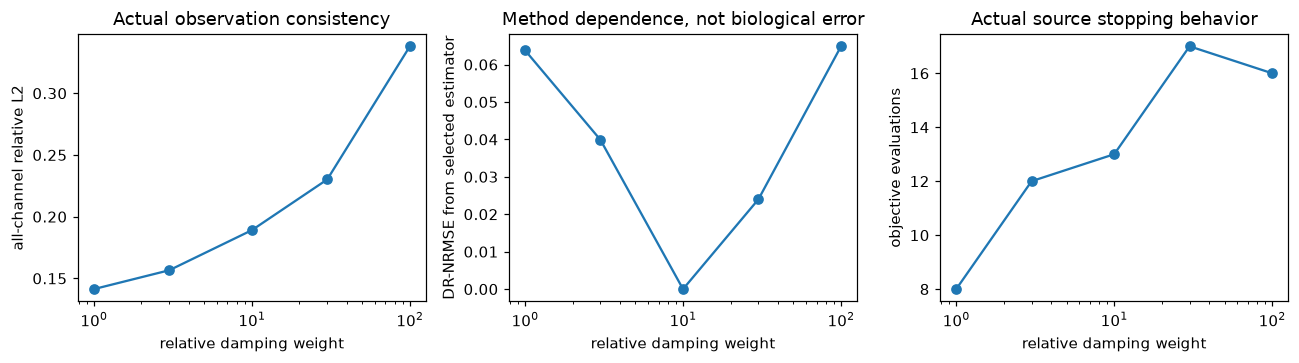

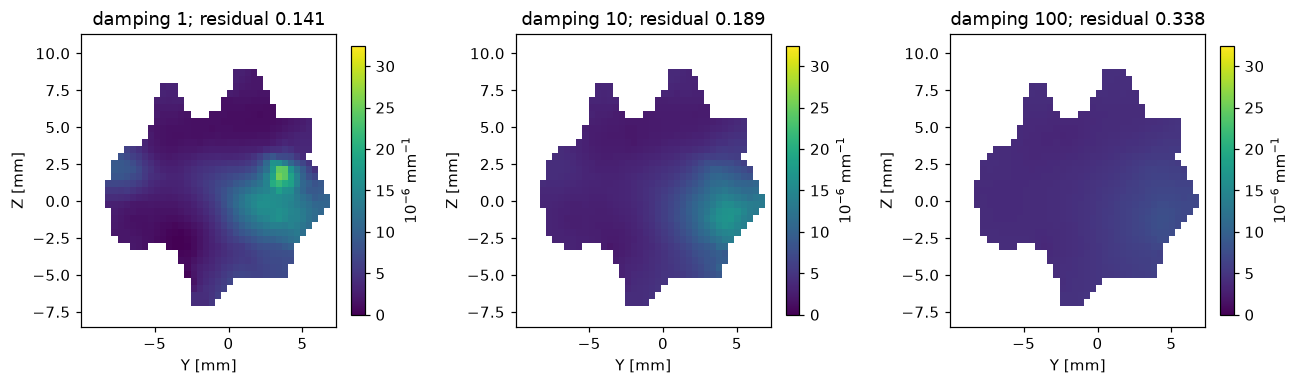

In [6]:
weights=[1.,3.,10.,30.,100.];sensitivity=[]
for weight in weights:
 result=fresh if weight==10 else reconstruct(raw,regularization=weight)
 sensitivity.append(result)
field_stack=np.asarray([r['reconstruction'] for r in sensitivity]);forward=np.asarray([r['forward_relative_L2'] for r in sensitivity]);stops=np.asarray([len(r['objective_history']) for r in sensitivity]);variation=np.asarray([metrics(r['reconstruction'],qualified_upstream)['dr_nrmse'] for r in sensitivity])
fig,axes=plt.subplots(1,3,figsize=(12,3.4));axes[0].semilogx(weights,forward,'o-');axes[0].set(xlabel='relative damping weight',ylabel='all-channel relative L2',title='Actual observation consistency');axes[1].semilogx(weights,variation,'o-');axes[1].set(xlabel='relative damping weight',ylabel='DR-NRMSE from selected estimator',title='Method dependence, not biological error');axes[2].semilogx(weights,stops,'o-');axes[2].set(xlabel='relative damping weight',ylabel='objective evaluations',title='Actual source stopping behavior');fig.tight_layout();show(fig,'figure09_regularization_sensitivity',weights=np.asarray(weights),full_fields=field_stack,forward_relative_L2=forward,evaluations=stops,variation_dr_nrmse=variation)
fig,axes=plt.subplots(1,3,figsize=(12,3.6));selected=[0,2,4];vmin=field_stack[selected].min()*1e6;vmax=field_stack[selected].max()*1e6
for ax,k in zip(axes,selected):
 a,b,v=slice_field(nodes,elements,field_stack[k],0,center[0]);im=ax.pcolormesh(a,b,v*1e6,shading='auto',cmap='viridis',vmin=vmin,vmax=vmax);ax.set(xlabel='Y [mm]',ylabel='Z [mm]',title=f'damping {weights[k]:g}; residual {forward[k]:.3f}');ax.set_aspect('equal');fig.colorbar(im,ax=ax,fraction=.045,label='$10^{-6}$ mm$^{-1}$')
fig.tight_layout();show(fig,'figure10_regularization_fields',selected_weights=np.asarray(weights)[selected],full_fields=field_stack[selected])


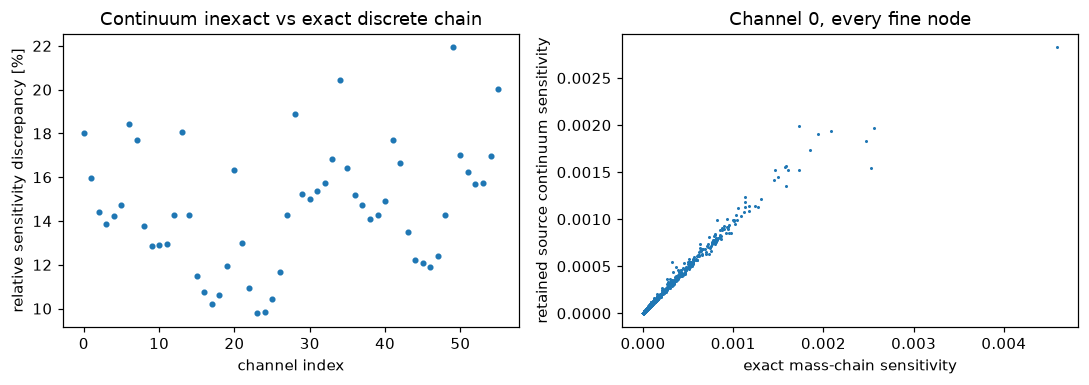

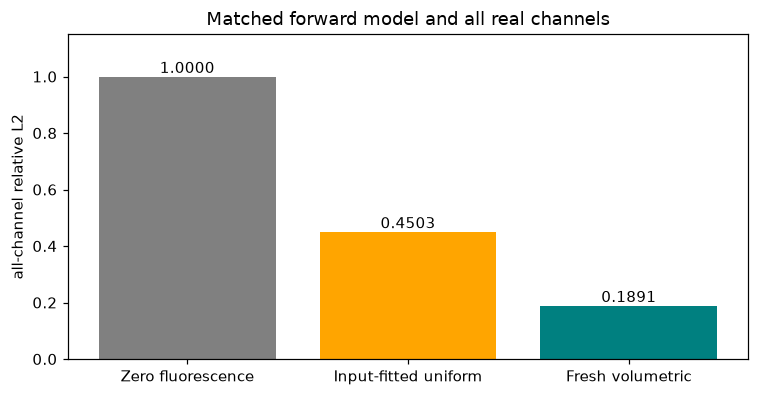

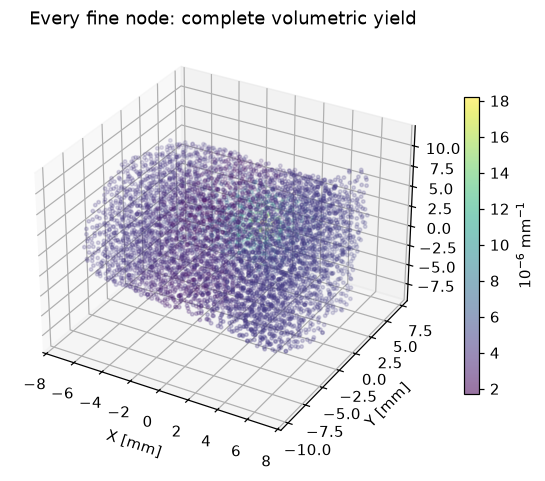

{
  "fresh_seconds": 3.402930300013395,
  "fields": 1,
  "nodes_scored": 5707,
  "channels_scored": 56,
  "fresh_vs_qualified_native": {
    "ncc": 0.9999999999999996,
    "dr_nrmse": 1.334059709477387e-12,
    "max_abs_mm_inverse": 1.623406406048647e-16
  },
  "full_forward_relative_L2": 0.18907149090792041,
  "uniform_forward_relative_L2": 0.4502997095693148,
  "evaluation_count": 13,
  "fresh_min_max_yield": [
    1.7355211163908486e-06,
    1.8207394401361556e-05
  ]
}


In [7]:
# Independent exact nodal mass-chain versus retained continuum inexact sensitivity.
# This compares mathematical operators; it does not generate new observations.
aphysical=lu.solve(D.T.toarray());chain=np.asarray([fresh['phix'][:,s]*(mass@aphysical[:,d]) for s,d in raw['links']]);continuum=fresh['prejacobian'].real
relative_rows=np.linalg.norm(continuum-chain,axis=1)/np.linalg.norm(chain,axis=1)
fig,axes=plt.subplots(1,2,figsize=(10,3.6));axes[0].plot(relative_rows*100,'o',ms=3);axes[0].set(xlabel='channel index',ylabel='relative sensitivity discrepancy [%]',title='Continuum inexact vs exact discrete chain');sample=0;axes[1].plot(chain[sample],continuum[sample],'.',ms=2);axes[1].set(xlabel='exact mass-chain sensitivity',ylabel='retained source continuum sensitivity',title='Channel 0, every fine node');fig.tight_layout();show(fig,'figure11_inexact_jacobian',row_relative_discrepancy=relative_rows,exact_chain=chain,source_continuum=continuum)
nulls=np.array([1.,np.linalg.norm(uniform_prediction-observed)/np.linalg.norm(observed),fresh['forward_relative_L2']]);fig,ax=plt.subplots(figsize=(7,3.7));bars=ax.bar(['Zero fluorescence','Input-fitted uniform','Fresh volumetric'],nulls,color=['gray','orange','teal']);ax.bar_label(bars,fmt='%.4f');ax.set(ylabel='all-channel relative L2',ylim=(0,1.15),title='Matched forward model and all real channels');fig.tight_layout();show(fig,'figure12_physical_nulls',relative_L2=nulls,uniform_field=uniform,volumetric_field=x)
fig=plt.figure(figsize=(7,5));ax=fig.add_subplot(111,projection='3d');im=ax.scatter(*nodes.T,c=x*1e6,s=5,alpha=.55,cmap='viridis');ax.set(xlabel='X [mm]',ylabel='Y [mm]',zlabel='Z [mm]',title='Every fine node: complete volumetric yield');fig.colorbar(im,ax=ax,shrink=.7,label='$10^{-6}$ mm$^{-1}$');show(fig,'figure13_complete_volume',nodes=nodes,yield_field=x)
summary={'fresh_seconds':runtime,'fields':1,'nodes_scored':len(x),'channels_scored':len(observed),'fresh_vs_qualified_native':comparison,'full_forward_relative_L2':fresh['forward_relative_L2'],'uniform_forward_relative_L2':float(nulls[1]),'evaluation_count':len(history),'fresh_min_max_yield': [float(x.min()),float(x.max())]};print(json.dumps(summary,indent=2))
if os.environ.get('IMAGING_FIGURE_DIR'):
 directory=Path(os.environ['IMAGING_FIGURE_DIR']);figures=[json.loads(p.read_text()) for p in sorted(directory.glob('figure[0-9]*.json'))];(directory/'figure_index.json').write_text(json.dumps({'summary':summary,'figures':figures},indent=2),encoding='utf8')


# 6. Conclusion and limits

The notebook actively reconstructed the complete real bound acquisition and scored every fine node. Fresh local results reproduce the qualified native method within the independently frozen numerical criteria and improve observation consistency over the matched uniform-field null. The original boundary defect is independently demonstrated and remains visible as a separate failed-source result.

A small observation residual does not establish spatial truth: 56 channels constrain 3,323 coarse spatial variables, and regularization visibly changes the field. Bulk optical coefficients, excitation normalization, the diffusion approximation, coarse-basis boundary fallback and retained inexact adjoint all condition the result. There is no claim of absolute probe concentration, tumor delineation accuracy or disease diagnosis. The source code license and unspecified separate sample-data redistribution rights are distinct. All graphics are paired with the actual numerical arrays in the private export directory.